# 04 · Rerun with a new tuning rule: fixed grid + smoothing

The first run (notebooks 02 and 03) picked each model's settings with **randomized search** (12–20 random draws) and kept the **single highest** practice score. Its validation curves showed that this can pick a narrow spike (KNN with 93 neighbours won 2007–2011, about 0.01 above its neighbours) or a point at the edge of a plateau, and random draws leave gaps in the range.

This notebook reruns the whole pipeline with a new rule. The full recipe was written and committed to GitHub **before any rerun result existed** ([docs/rerun_recipe.md](../docs/rerun_recipe.md)). The rerun was prompted by the validation charts, after the first test result had been seen, so both test results are reported side by side, whichever is better.

**How the best setting of a model is defined (every model, every predicted year):**
1. **Fixed grid:** every combination in the model's grid is scored.
2. **Score:** mean macro-F1 over the same 5 practice blocks as before.
3. **Smooth:** each setting's score becomes the average of its own score and its grid neighbours one step away on each numeric setting. Categorical settings are never averaged across.
4. **Pick:** highest smoothed score; ties (3 decimals) go to the simpler setting. A winner on the edge of a numeric range is flagged.

**How the Sell cut-off is defined (shortlisted models, once, on 2005–2020):** each cut-off's total excess return is averaged with its neighbours (c ± 0.05), and the rule with the highest smoothed excess return is picked. The model ranking then uses that rule's actual results.

The grid tuning itself (535 settings × 5 practice blocks × 16 years, about 9 hours on 2 cores) was run by `src/grid_tuning.py` and saved per model and year in `results/v2/tune/`. This notebook loads those results.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from src.data import load_spy
from src.features import build_features, FEATURES
from src.labels import make_labels, CLASS_NAMES, CLASS_ORDER
from src.models import MODEL_NAMES, classification_scores, block_bootstrap_ci, macro_f1, always_buy_proba
from src.backtest import evaluate, signals_from_proba, FEE, SLIPPAGE
from src.grid_tuning import GRIDS, grid_points
from src.rerun_select import load_tuning, load_proba, cutoff_table, choose_rule, rank_models, slug, V2
from src import plotting as P
P.setup()
RES = ROOT / "results"
px = load_spy()
d = build_features(px).join(make_labels(px["close"])).dropna()
X, y = d[FEATURES], d["label"].astype(int)
VAL_YEARS, TEST_YEARS = list(range(2005, 2021)), list(range(2021, 2027))
tune = {m: load_tuning(m, VAL_YEARS) for m in MODEL_NAMES}
print({m: len(t) for m, t in tune.items()})

{'Dummy': 16, 'K-nearest neighbours': 16, 'Logistic regression': 16, 'Decision tree': 16, 'Random forest': 16, 'HistGradientBoosting': 16, 'XGBoost': 16, 'Perceptron': 16, 'MLP': 16}


## 1. The grids

In [2]:
rows = []
for m in MODEL_NAMES:
    g = GRIDS[m]
    rows.append({"model": m, "grid": " × ".join(f"{k} ({len(v)})" for k, v in g["axes"].items()),
                 "smoothed across": ", ".join(g["numeric"]) or "—",
                 "fixed": ", ".join(f"{k} = {v}" for k, v in g["fixed"].items()) or "—",
                 "settings": len(grid_points(m)[1])})
pd.DataFrame(rows).set_index("model")

,grid,smoothed across,fixed,settings
model,,,,
Dummy,strategy (2),—,—,2
K-nearest neighbours,n_neighbors (40) × weights (2),n_neighbors,—,80
Logistic regression,C (17) × l1_ratio (2),C,—,34
Decision tree,max_depth (7) × min_samples_leaf (9),"max_depth, min_samples_leaf",—,63
Random forest,max_depth (8) × min_samples_leaf (5) × max_fea...,"max_depth, min_samples_leaf",n_estimators = 300,80
HistGradientBoosting,learning_rate (7) × max_iter (5) × l2_regulari...,"learning_rate, max_iter, l2_regularization",max_leaf_nodes = 31,105
XGBoost,learning_rate (7) × n_estimators (5) × colsamp...,"learning_rate, n_estimators, colsample_bytree","max_depth = 6, subsample = 1.0",105
Perceptron,alpha (13) × penalty (3),alpha,—,39
MLP,learning_rate_init (9) × hidden_layer_sizes (3),learning_rate_init,alpha = 0.0001,27


## 2. What smoothing does: KNN, 2008

The first run's winner was 93 neighbours (uniform), a narrow spike. Below: every grid point's practice score (dots), the smoothed score (line), and the train score (dashed, display only).

train score is much higher than practice score at small k (memorising):  n_neighbors  train  mean
           5  0.674 0.325
          10  0.611 0.328


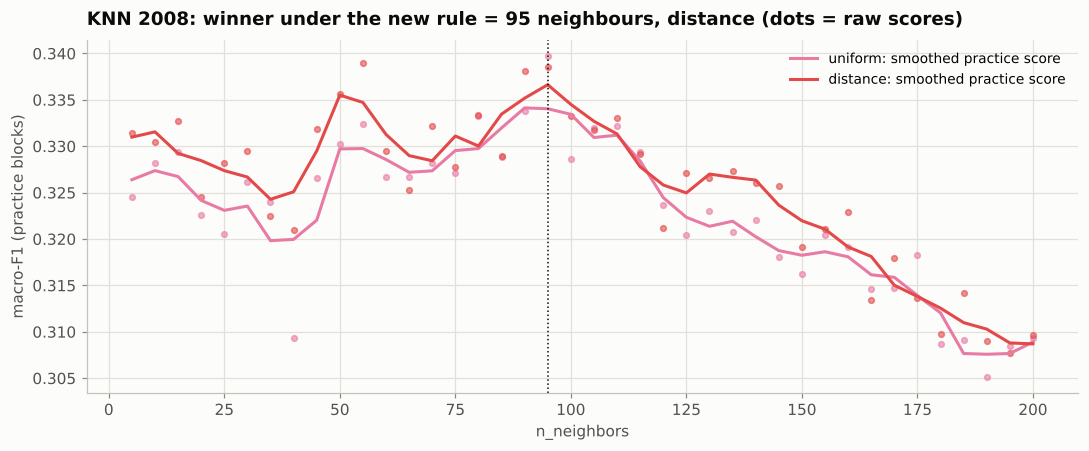

In [3]:
r = tune["K-nearest neighbours"][2008]
g = pd.DataFrame([{**x["params"], "mean": x["mean"], "smoothed": x["smoothed"], "train": x["train_mean"]} for x in r["grid"]])
w = r["grid"][r["winner"]]["params"]
fig, ax = plt.subplots(figsize=(10, 4.2))
for wt, col in [("uniform", P.MODEL_COLORS["K-nearest neighbours"]), ("distance", P.CLASS_COLORS["Sell"])]:
    s = g[g.weights == wt]
    ax.scatter(s.n_neighbors, s["mean"], s=14, color=col, alpha=.6)
    ax.plot(s.n_neighbors, s["smoothed"], color=col, lw=2, label=f"{wt}: smoothed practice score")
ax.axvline(w["n_neighbors"], color=P.INK, ls=":", lw=1)
ax.set_xlabel("n_neighbors"); ax.set_ylabel("macro-F1 (practice blocks)")
ax.set_title(f"KNN 2008: winner under the new rule = {w['n_neighbors']} neighbours, {w['weights']} (dots = raw scores)")
ax.legend(); fig.tight_layout(); P.save(fig, "04_knn_2008_smoothing")
print("train score is much higher than practice score at small k (memorising):",
      g[(g.weights == "uniform") & (g.n_neighbors <= 10)][["n_neighbors", "train", "mean"]].round(3).to_string(index=False))

## 3. Winning settings per model and year (2005–2020)

In [4]:
rows = []
for m in MODEL_NAMES:
    for yr, r in tune[m].items():
        x = r["grid"][r["winner"]]
        rows.append({"model": m, "year": yr, "winner": ", ".join(f"{k}={v}" for k, v in x["params"].items()),
                     "raw": x["mean"], "smoothed": x["smoothed"], "edge": ", ".join(r["edge"]),
                     "raw best was a different setting": r["raw_best"] != r["winner"]})
win = pd.DataFrame(rows)
print("Share of model-years where the smoothed winner differs from the raw best:", f"{win['raw best was a different setting'].mean():.0%}")
print("Share of model-years with an edge flag:", f"{(win['edge'] != '').mean():.0%}")
win.groupby("model").agg(years=("year", "size"), differs=("raw best was a different setting", "sum"),
                         edge_flags=("edge", lambda s: (s != "").sum()))

Share of model-years where the smoothed winner differs from the raw best: 58%
Share of model-years with an edge flag: 51%


,years,differs,edge_flags
model,,,
Decision tree,16,9,5
Dummy,16,0,0
HistGradientBoosting,16,13,14
K-nearest neighbours,16,10,0
Logistic regression,16,8,12
MLP,16,5,10
Perceptron,16,14,4
Random forest,16,9,15
XGBoost,16,15,14


## 4. Old rule vs new rule vs library defaults (2005–2020)

Display only: none of this was used to choose anything. Macro-F1 over all validation days, and the number of years the new rule beats the old one.

In [5]:
yy = lambda p: y.loc[p.index]
rows, per_year = [], []
for m in MODEL_NAMES:
    new = load_proba(m, VAL_YEARS)
    old = pd.read_parquet(RES / f"val_proba_{slug(m)}.parquet")
    dfl = pd.read_parquet(V2 / "defaults" / f"val_proba_{slug(m)}.parquet")
    f = lambda d_, yr=None: macro_f1(yy(d_ if yr is None else d_[d_.year == yr]), (d_ if yr is None else d_[d_.year == yr])["pred"])
    yrs = pd.DataFrame({"new": [f(new, yr) for yr in VAL_YEARS], "old": [f(old, yr) for yr in VAL_YEARS], "defaults": [f(dfl, yr) for yr in VAL_YEARS]}, index=VAL_YEARS)
    rows.append({"model": m, "old rule": f(old), "new rule": f(new), "library defaults": f(dfl),
                 "years new > old": int((yrs.new > yrs.old + 1e-9).sum()), "years new > defaults": int((yrs.new > yrs.defaults + 1e-9).sum())})
cmp_ = pd.DataFrame(rows).set_index("model").sort_values("new rule", ascending=False)
cmp_.style.format({"old rule": "{:.3f}", "new rule": "{:.3f}", "library defaults": "{:.3f}"})

,old rule,new rule,library defaults,years new > old,years new > defaults
model,,,,,
Random forest,0.421,0.424,0.404,9,7
Logistic regression,0.421,0.423,0.419,10,11
K-nearest neighbours,0.414,0.416,0.365,10,14
MLP,0.423,0.412,0.425,7,8
Decision tree,0.400,0.408,0.380,9,7
XGBoost,0.399,0.399,0.396,9,7
HistGradientBoosting,0.391,0.393,0.390,7,8
Perceptron,0.357,0.372,0.332,9,12
Dummy,0.340,0.340,0.202,0,16


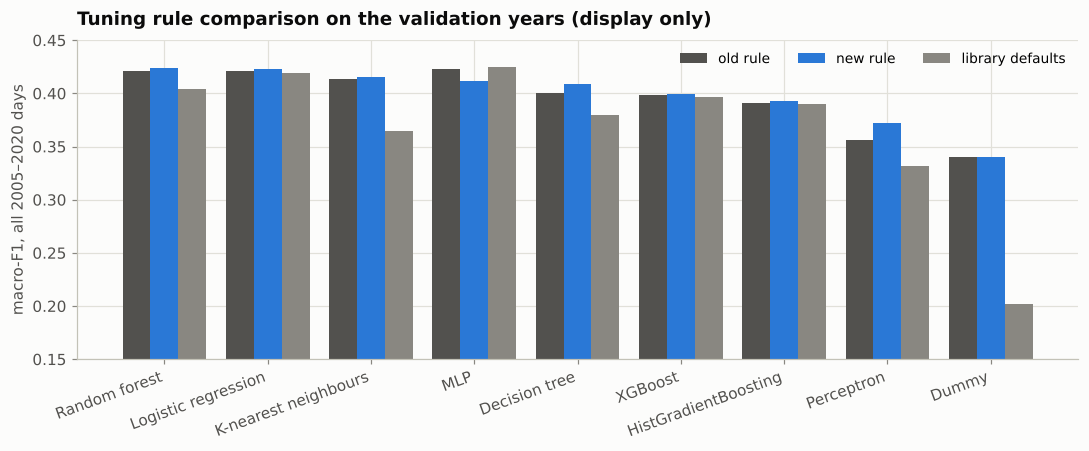

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
x_ = np.arange(len(cmp_)); w_ = 0.27
for k, (col, c) in enumerate([("old rule", P.BENCHMARK), ("new rule", P.MODEL_COLORS["Logistic regression"]), ("library defaults", P.CLASS_COLORS["Hold"])]):
    ax.bar(x_ + (k - 1) * w_, cmp_[col], w_, label=col, color=c)
ax.set_xticks(x_, cmp_.index, rotation=20, ha="right"); ax.set_ylim(0.15, 0.45); ax.set_ylabel("macro-F1, all 2005–2020 days")
ax.legend(ncol=3); ax.set_title("Tuning rule comparison on the validation years (display only)")
fig.tight_layout(); P.save(fig, "04_old_new_defaults")

## 5. All 9 models on 2005–2020 (new rule)

Classification scores on all validation days, and the money result of the plain "highest probability wins" rule for every model (one account 2005–2020, with costs, against Buy & Hold).

In [7]:
y_val = y[(y.index.year >= 2005) & (y.index.year <= 2020)]
val_proba = {m: load_proba(m, VAL_YEARS) for m in MODEL_NAMES}
val_proba["Always predict Buy"] = always_buy_proba(y_val.index, y_val.index.year)
rows = []
for m, p in val_proba.items():
    s = classification_scores(y_val, p["pred"].reindex(y_val.index))
    r = evaluate(px, p, None, years=VAL_YEARS)
    rows.append({"model": m, **s, "years_won": r["years won"], "years_tied": r["years tied"], "median_sharpe": r["median yearly Sharpe"],
                 "worst_year": r["worst year excess"], "excess": r["excess total return"]})
comparison = pd.DataFrame(rows).set_index("model").sort_values("macro_f1", ascending=False)
comparison.reset_index().to_json(V2 / "comparison_v2.json", orient="records", indent=1)
comparison.style.format({"macro_f1": "{:.3f}", "balanced_acc": "{:.3f}", "accuracy": "{:.3f}", "median_sharpe": "{:.2f}", "worst_year": "{:+.0%}", "excess": "{:+.0%}"})

,macro_f1,balanced_acc,accuracy,years_won,years_tied,median_sharpe,worst_year,excess
model,,,,,,,,
Random forest,0.424,0.435,0.470,4,0,0.43,-29%,-246%
Logistic regression,0.423,0.433,0.484,3,1,0.47,-28%,-193%
K-nearest neighbours,0.416,0.423,0.455,3,0,0.48,-25%,-298%
MLP,0.412,0.417,0.446,3,0,0.25,-32%,-300%
Decision tree,0.408,0.410,0.436,4,0,0.38,-23%,-273%
XGBoost,0.399,0.401,0.431,2,0,0.11,-19%,-299%
HistGradientBoosting,0.393,0.394,0.422,1,0,0.32,-17%,-285%
Perceptron,0.372,0.375,0.383,3,0,0.22,-31%,-267%
Dummy,0.340,0.341,0.354,1,0,-0.16,-33%,-374%


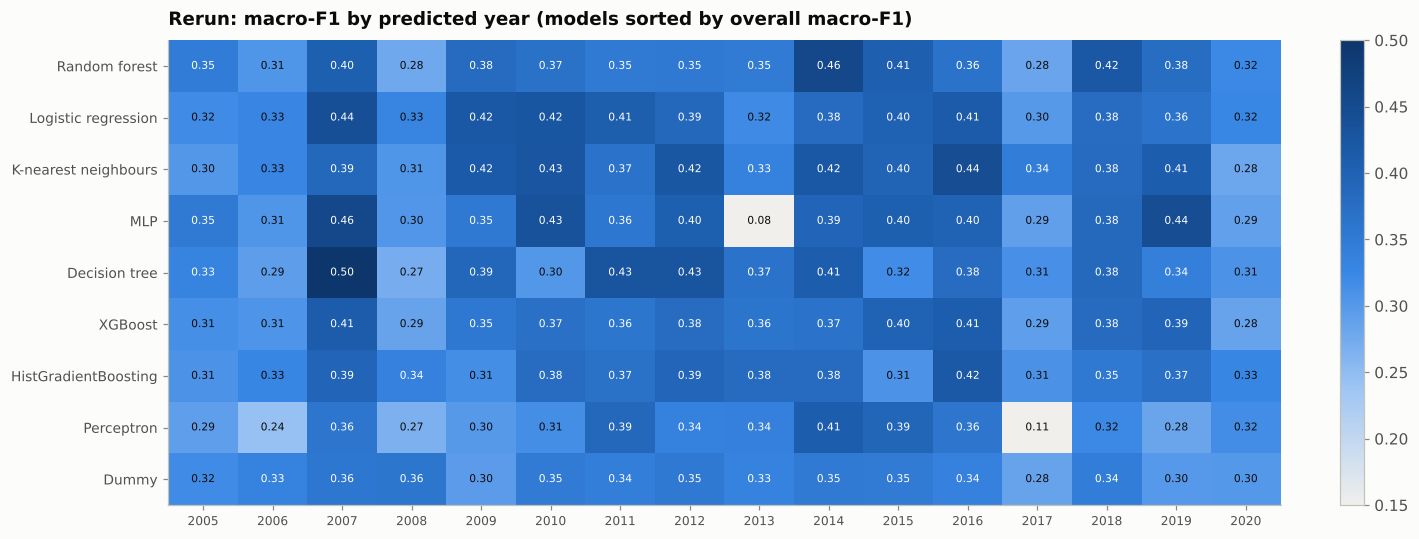

In [8]:
order = [m for m in comparison.index if m != "Always predict Buy"]
per_year = pd.DataFrame({m: [macro_f1(y_val[y_val.index.year == yr], val_proba[m]["pred"].reindex(y_val.index)[y_val.index.year == yr]) for yr in VAL_YEARS] for m in order}, index=VAL_YEARS).T
fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(per_year.values, cmap=P.SEQUENTIAL, aspect="auto", vmin=0.15, vmax=0.5)
ax.set_xticks(range(per_year.shape[1]), per_year.columns, fontsize=8); ax.set_yticks(range(per_year.shape[0]), per_year.index, fontsize=9)
for i in range(per_year.shape[0]):
    for j in range(per_year.shape[1]):
        v = per_year.iat[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.33 else P.INK)
ax.grid(False); ax.set_title("Rerun: macro-F1 by predicted year (models sorted by overall macro-F1)")
fig.colorbar(im, ax=ax, fraction=0.02); fig.tight_layout(); P.save(fig, "04_macro_f1_by_year")

## 6. Shortlist and the smoothed Sell cut-off (2005–2020)

In [9]:
pooled = cmp_["new rule"].drop("Dummy").sort_values(ascending=False)
shortlist = list(pooled.index[:3])
print("Shortlist (top 3 by macro-F1, new rule):", shortlist)
tabs, best = {}, {}
for m in shortlist:
    t, _ = cutoff_table(px, load_proba(m, VAL_YEARS), VAL_YEARS)
    tabs[m], best[m] = t, choose_rule(t)
    print(f"{m}: picked {best[m]}")
pd.concat({m: tabs[m].set_index("rule")[["excess return", "smoothed excess return", "Sharpe", "years won", "worst year excess", "trades", "costs $"]] for m in shortlist}).style.format(
    {"excess return": "{:+.0%}", "smoothed excess return": "{:+.0%}", "Sharpe": "{:.2f}", "worst year excess": "{:+.0%}", "costs $": "{:,.0f}"})

Shortlist (top 3 by macro-F1, new rule): ['Random forest', 'Logistic regression', 'K-nearest neighbours']


Random forest: picked c = 0.60


Logistic regression: picked c = 0.45


K-nearest neighbours: picked c = 0.55


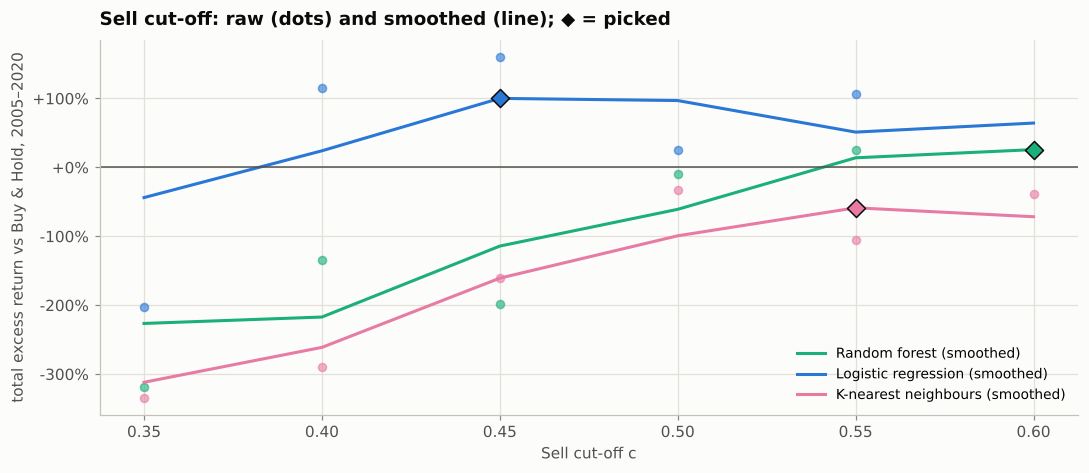

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.4))
for m in shortlist:
    t = tabs[m][tabs[m]["c"].notna()]
    col = P.MODEL_COLORS[m]
    ax.scatter(t["c"], t["excess return"], color=col, s=28, alpha=.6)
    ax.plot(t["c"], t["smoothed excess return"], color=col, lw=2, label=f"{m} (smoothed)")
    c_ = float(best[m].split("= ")[1]) if best[m] != "highest prob." else None
    if c_ is not None:
        ax.scatter([c_], t.loc[t["c"].sub(c_).abs() < 1e-9, "smoothed excess return"], marker="D", s=70, color=col, edgecolor=P.INK, zorder=5)
ax.axhline(0, color=P.INK2, lw=1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_xlabel("Sell cut-off c"); ax.set_ylabel("total excess return vs Buy & Hold, 2005–2020")
ax.set_title("Sell cut-off: raw (dots) and smoothed (line); ◆ = picked")
ax.legend(); fig.tight_layout(); P.save(fig, "04_cutoff_chart")

In [11]:
score = pd.DataFrame([{**tabs[m].set_index("rule").loc[best[m]].to_dict(), "model": m, "rule": best[m], "macro-F1 rank": k + 1}
                      for k, m in enumerate(shortlist)]).set_index("model")
score, chosen = rank_models(score)
chosen_rule = best[chosen]
chosen_c = None if chosen_rule == "highest prob." else float(chosen_rule.split("= ")[1])
frozen = json.load(open(V2 / "final_recipe_v2.json"))
assert frozen["model"] == chosen and frozen["rule"] == chosen_rule, "recomputed recipe differs from the frozen one"
print(f"FINAL RECIPE (frozen and committed before the test run): {chosen}, {chosen_rule}")
score[["macro-F1 rank", "rule", "excess return", "smoothed excess return", "years won", "median yearly Sharpe", "worst year excess", "rank total", "picked"]].style.format(
    {"excess return": "{:+.0%}", "smoothed excess return": "{:+.0%}", "median yearly Sharpe": "{:.2f}", "worst year excess": "{:+.0%}", "rank total": "{:.0f}"})

FINAL RECIPE (frozen and committed before the test run): Logistic regression, c = 0.45


,macro-F1 rank,rule,excess return,smoothed excess return,years won,median yearly Sharpe,worst year excess,rank total,picked
model,,,,,,,,,
Random forest,1,c = 0.60,+26%,+26%,3.000000,0.90,-0%,6,
Logistic regression,2,c = 0.45,+160%,+100%,5.000000,0.90,-8%,3,✓
K-nearest neighbours,3,c = 0.55,-105%,-59%,2.000000,0.73,-7%,9,


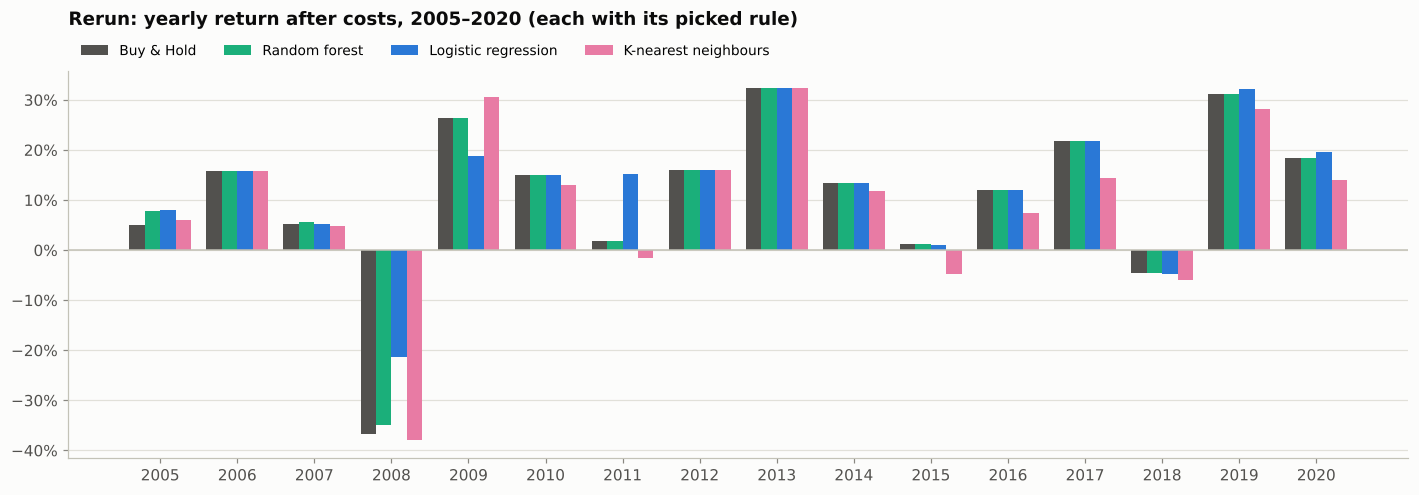

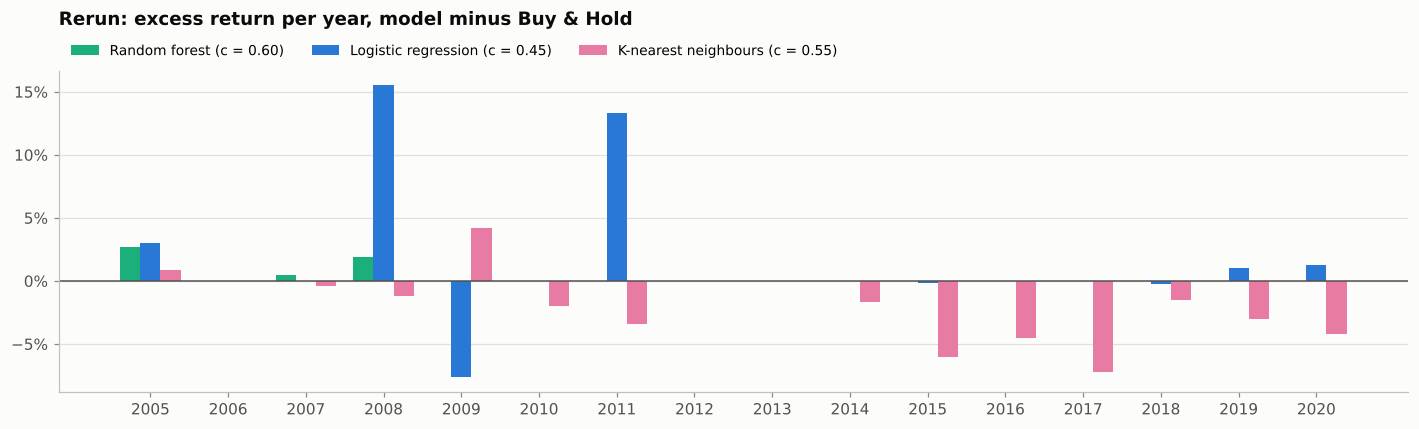

In [12]:
runs = {m: cutoff_table.__globals__["evaluate"](px, load_proba(m, VAL_YEARS), None if best[m] == "highest prob." else float(best[m].split("= ")[1]), years=VAL_YEARS) for m in shortlist}
yrs = VAL_YEARS
fig, ax = plt.subplots(figsize=(13, 4.6)); w = 0.2
series = [("Buy & Hold", runs[shortlist[0]]["yearly"]["B&H return"])] + [(m, runs[m]["yearly"]["model return"]) for m in shortlist]
for k, (name, s_) in enumerate(series):
    ax.bar(np.arange(len(yrs)) + (k - 1.5) * w, s_.reindex(yrs).values, width=w, color=P.MODEL_COLORS[name], label=name)
ax.axhline(0, color=P.AXIS, lw=1); ax.set_xticks(range(len(yrs)), yrs); P.pct(ax); ax.grid(axis="x", visible=False)
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0)); ax.set_title("Rerun: yearly return after costs, 2005–2020 (each with its picked rule)", pad=30)
fig.tight_layout(); P.save(fig, "04_val_return_by_year")
fig, ax = plt.subplots(figsize=(13, 4))
for k, m in enumerate(shortlist):
    ex_ = runs[m]["yearly"]["excess return"].reindex(yrs)
    ax.bar(np.arange(len(yrs)) + (k - 1) * 0.26, ex_.values, width=0.26, color=P.MODEL_COLORS[m], label=f"{m} ({best[m]})")
ax.axhline(0, color=P.INK2, lw=1); ax.set_xticks(range(len(yrs)), yrs); P.pct(ax); ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0)); ax.set_title("Rerun: excess return per year, model minus Buy & Hold", pad=30)
fig.tight_layout(); P.save(fig, "04_val_excess_by_year")
score.reset_index().to_json(V2 / "scorecard_v2.json", orient="records", indent=1, default_handler=str)
json.dump({m: tabs[m].assign(c=tabs[m]["c"].astype(object).where(tabs[m]["c"].notna(), None)).to_dict(orient="records") for m in shortlist}, open(V2 / "cutoff_tables_v2.json", "w"), indent=1, default=float)

## 7. The test, 2021 → latest, opened once

The frozen recipe is retrained and re-tuned (same grid + smoothing) each test year on all data before that year.

In [13]:
test_proba = {chosen: load_proba(chosen, TEST_YEARS), "Dummy": load_proba("Dummy", TEST_YEARS)}
idx = test_proba[chosen].index
test_proba["Always predict Buy"] = always_buy_proba(idx, idx.year)
y_test = y.loc[idx]
print(f"Test rows: {len(y_test):,}, {y_test.index[0].date()} to {y_test.index[-1].date()}")
print("Settings used each test year:")
for yr, r in load_tuning(chosen, TEST_YEARS).items():
    print(" ", yr, r["grid"][r["winner"]]["params"])
rows = []
preds = {"Dummy": test_proba["Dummy"]["pred"], "Always predict Buy": test_proba["Always predict Buy"]["pred"],
         chosen: test_proba[chosen]["pred"], f"{chosen} with {chosen_rule}": signals_from_proba(test_proba[chosen], chosen_c)}
for name, pr in preds.items():
    pr = pr.reindex(y_test.index)
    s = classification_scores(y_test, pr)
    lo, hi = block_bootstrap_ci(y_test.values, pr.values, macro_f1)
    rows.append({"model": name, **s, "macro_f1 95% CI": f"{lo:.3f} to {hi:.3f}"})
test_scores = pd.DataFrame(rows).set_index("model")
test_scores

Test rows: 1,449, 2021-01-04 to 2026-10-09
Settings used each test year:
  2021 {'C': 0.01778279, 'l1_ratio': 0.0}
  2022 {'C': 0.01778279, 'l1_ratio': 0.0}
  2023 {'C': 0.01, 'l1_ratio': 0.0}
  2024 {'C': 0.01778279, 'l1_ratio': 0.0}
  2025 {'C': 0.01778279, 'l1_ratio': 0.0}
  2026 {'C': 0.03162278, 'l1_ratio': 0.0}


,macro_f1,balanced_acc,accuracy,macro_f1 95% CI
model,,,,
Dummy,0.340876,0.341395,0.351277,0.312 to 0.366
Always predict Buy,0.181727,0.333333,0.374741,0.167 to 0.195
Logistic regression,0.399790,0.406257,0.429952,0.368 to 0.432
Logistic regression with c = 0.45,0.332654,0.375607,0.429952,0.304 to 0.359


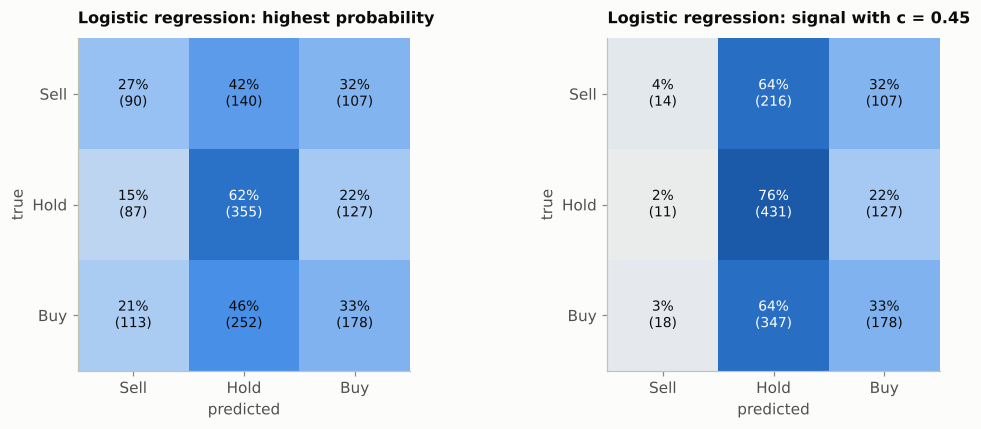

In [14]:
names = [CLASS_NAMES[c] for c in CLASS_ORDER]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, pr) in zip(axes, [(f"{chosen}: highest probability", test_proba[chosen]["pred"]),
                                  (f"{chosen}: signal with {chosen_rule}", signals_from_proba(test_proba[chosen], chosen_c))]):
    cm = confusion_matrix(y_test, pr.reindex(y_test.index), labels=CLASS_ORDER)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap=P.SEQUENTIAL, vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cmn[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center", fontsize=9, color="white" if cmn[i, j] > 0.55 else P.INK)
    ax.set_xticks(range(3), names); ax.set_yticks(range(3), names); ax.grid(False)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=10.5)
fig.tight_layout(); P.save(fig, "04_test_confusion")

In [15]:
test_run = evaluate(px, test_proba[chosen], chosen_c, years=TEST_YEARS)
test_sym = evaluate(px, test_proba[chosen], None, years=TEST_YEARS)
test_free = evaluate(px, test_proba[chosen], chosen_c, years=TEST_YEARS, fee=0.0, slippage=0.0)
sm, sb = test_run["model"], test_run["bh_summary"]
headline = pd.DataFrame({f"{chosen} ({chosen_rule})": sm, "Buy & Hold": sb,
                         f"{chosen} (highest prob.)": test_sym["model"], f"{chosen} ({chosen_rule}), zero costs": test_free["model"]}).T
headline.style.format({"start value $": "${:,.0f}", "end value $": "${:,.0f}", "total return": "{:+.1%}", "CAGR": "{:+.1%}",
                       "Sharpe": "{:.2f}", "max drawdown": "{:.1%}", "% time invested": "{:.0%}", "costs paid $": "${:,.0f}", "costs % of start": "{:.2%}"})

,start value $,end value $,total return,CAGR,Sharpe,max drawdown,trades,% time invested,costs paid $,costs % of start
Logistic regression (c = 0.45),"$10,000","$20,500",+105.0%,+13.3%,0.88,-30.3%,31.000000,95%,$524,5.24%
Buy & Hold,"$10,000","$22,787",+127.9%,+15.3%,0.95,-24.5%,1.000000,100%,$15,0.15%
Logistic regression (highest prob.),"$10,000","$12,362",+23.6%,+3.7%,0.35,-25.5%,156.000000,56%,"$2,548",25.48%
"Logistic regression (c = 0.45), zero costs","$10,000","$21,475",+114.8%,+14.2%,0.93,-28.8%,31.000000,95%,$0,0.00%


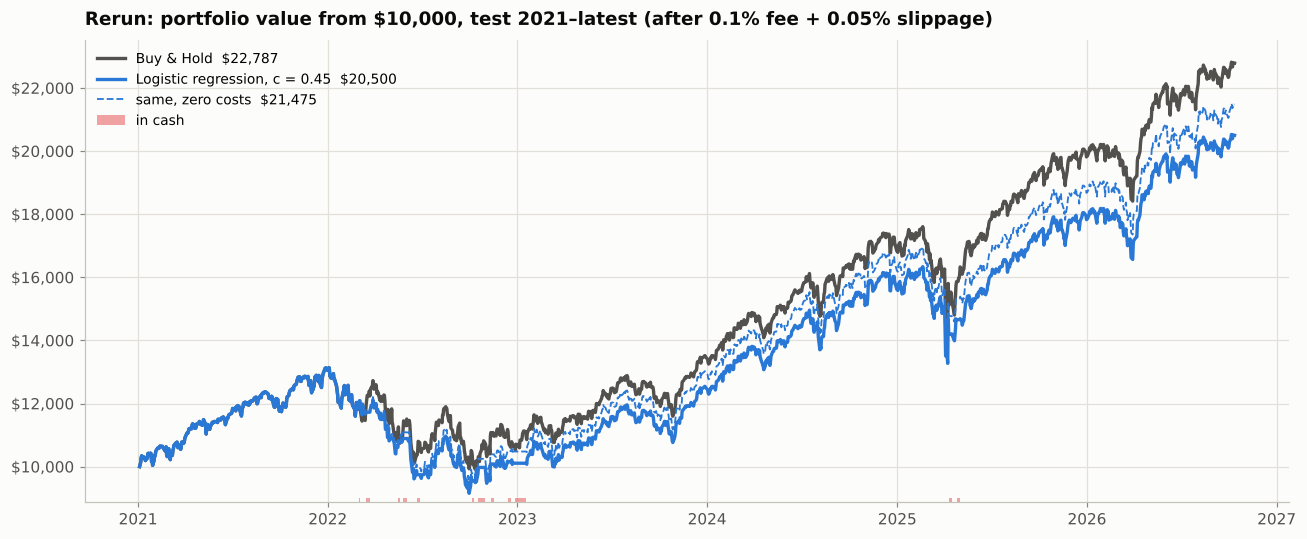

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test_run["bh"].value(), color=P.BENCHMARK, lw=2.2, label=f"Buy & Hold  ${sb['end value $']:,.0f}")
ax.plot(test_run["pf"].value(), color=P.MODEL_COLORS[chosen], lw=2.2, label=f"{chosen}, {chosen_rule}  ${sm['end value $']:,.0f}")
ax.plot(test_free["pf"].value(), color=P.MODEL_COLORS[chosen], lw=1.2, ls="--", label=f"same, zero costs  ${test_free['model']['end value $']:,.0f}")
inv = test_run["pf"].asset_value() > 0
ymin = min(test_run["pf"].value().min(), test_run["bh"].value().min()) * 0.97
ax.fill_between(inv.index, ymin, ymin * 1.015, where=~inv, color=P.CLASS_COLORS["Sell"], alpha=0.5, step="post", lw=0, label="in cash")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.legend(loc="upper left"); ax.set_ylim(bottom=ymin)
ax.set_title(f"Rerun: portfolio value from $10,000, test 2021–latest (after {FEE:.1%} fee + {SLIPPAGE:.2%} slippage)")
fig.tight_layout(); P.save(fig, "04_test_equity")

In [17]:
yt = test_run["yearly"][["model return", "B&H return", "excess return", "result", "model Sharpe", "B&H Sharpe", "trades", "% time invested"]]
print(f"Years won: {test_run['years won']} of {test_run['years']} (ties {test_run['years tied']}); "
      f"quarters won: {test_run['quarters won']} of {test_run['quarters']} (ties {test_run['quarters tied']})")
yt.style.format({"model return": "{:+.1%}", "B&H return": "{:+.1%}", "excess return": "{:+.1%}", "model Sharpe": "{:.2f}", "B&H Sharpe": "{:.2f}", "% time invested": "{:.0%}"})

Years won: 0 of 6 (ties 2); quarters won: 1 of 24 (ties 18)


,model return,B&H return,excess return,result,model Sharpe,B&H Sharpe,trades,% time invested
year,,,,,,,,
2021,+30.6%,+30.6%,+0.0%,loss,2.14,2.14,1,100%
2022,-22.6%,-18.2%,-4.4%,loss,-1.10,-0.71,23,78%
2023,+23.7%,+26.2%,-2.4%,loss,1.77,1.86,1,96%
2024,+24.9%,+24.9%,+0.0%,tie,1.83,1.83,0,100%
2025,+14.1%,+17.7%,-3.6%,loss,0.81,0.94,6,96%
2026,+15.0%,+15.0%,+0.0%,tie,1.46,1.46,0,100%


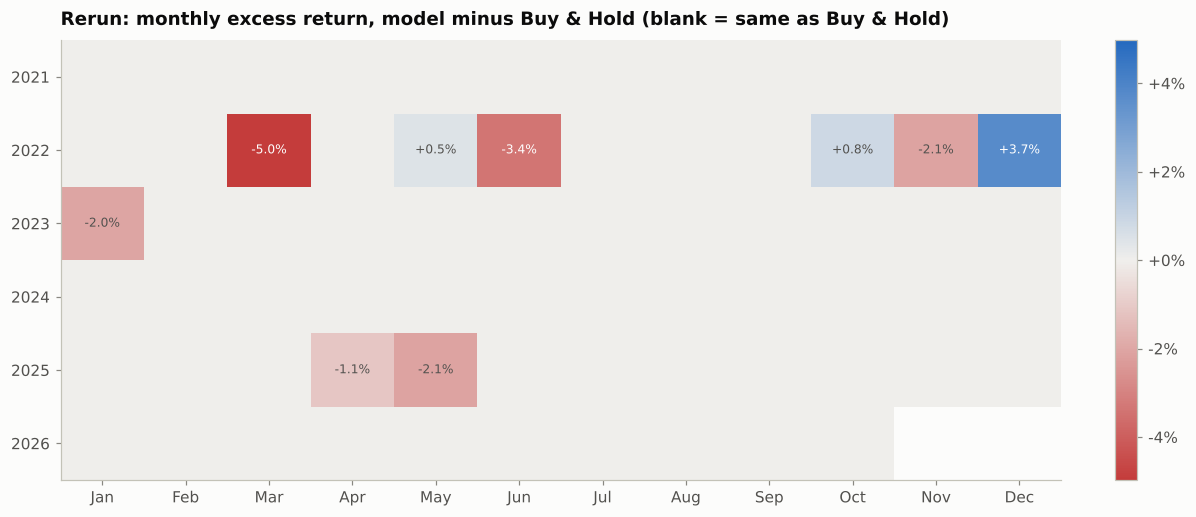

In [18]:
mv, bv = test_run["pf"].value(), test_run["bh"].value()
def month_ret(v):
    m = v.resample("ME").last()
    return m / pd.concat([pd.Series([v.iloc[0]]), m.iloc[:-1]]).set_axis(m.index) - 1
monthly = month_ret(mv) - month_ret(bv)
heat = monthly.groupby([monthly.index.year, monthly.index.month]).first().unstack()
heat.columns = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"][:heat.shape[1]] if heat.shape[1] == 12 else heat.columns
lim = max(0.02, np.nanmax(np.abs(heat.values)))
fig, ax = plt.subplots(figsize=(11, 0.6 * len(heat) + 1.2))
im = ax.imshow(heat.values, cmap=P.DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns); ax.set_yticks(range(len(heat)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iat[i, j]
        if pd.notna(v) and abs(v) >= 0.0005:
            ax.text(j, i, f"{v:+.1%}", ha="center", va="center", fontsize=8, color="white" if abs(v) > lim * 0.6 else P.INK2)
ax.grid(False); ax.set_title("Rerun: monthly excess return, model minus Buy & Hold (blank = same as Buy & Hold)")
fig.colorbar(im, ax=ax, fraction=0.03, format=plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
fig.tight_layout(); P.save(fig, "04_test_monthly_heatmap")

In [19]:
summary = {
    "data_last_date": str(px.index[-1].date()), "test_first_date": str(y_test.index[0].date()), "test_last_signal_date": str(y_test.index[-1].date()),
    "chosen_model": chosen, "rule": chosen_rule, "cutoff": chosen_c, "shortlist": shortlist,
    "test_macro_f1": float(test_scores.loc[chosen, "macro_f1"]), "dummy_macro_f1": float(test_scores.loc["Dummy", "macro_f1"]),
    "test_accuracy": float(test_scores.loc[chosen, "accuracy"]),
    "model": {k: float(v) for k, v in sm.items()}, "buy_hold": {k: float(v) for k, v in sb.items()},
    "zero_cost_model": {k: float(v) for k, v in test_free["model"].items()},
    "symmetric_rule_model": {k: float(v) for k, v in test_sym["model"].items()},
    "excess_total_return": float(test_run["excess total return"]), "excess_dollars": float(test_run["excess $"]),
    "years_won": test_run["years won"], "years_tied": test_run["years tied"], "years": test_run["years"],
    "quarters_won": test_run["quarters won"], "quarters_tied": test_run["quarters tied"], "quarters": test_run["quarters"],
    "yearly": test_run["yearly"].reset_index().to_dict(orient="records"),
}
json.dump(summary, open(V2 / "test_summary_v2.json", "w"), indent=1, default=str)

## 8. First run vs rerun on the test

In [20]:
old = json.load(open(RES / "test_summary.json"))
def row(s, label):
    return {"run": label, "model + rule": f"{s['chosen_model']}, {s['rule']}", "macro-F1": s["test_macro_f1"],
            "end value $": s["model"]["end value $"], "Buy & Hold $": s["buy_hold"]["end value $"],
            "excess $": s["excess_dollars"], "Sharpe": s["model"]["Sharpe"], "max drawdown": s["model"]["max drawdown"],
            "trades": s["model"]["trades"], "years won": f"{s['years_won']} of {s['years']} ({s['years_tied']} tied)"}
pd.DataFrame([row(old, "first run (random search, highest score)"), row(summary, "rerun (grid + smoothing)")]).set_index("run").style.format(
    {"macro-F1": "{:.3f}", "end value $": "${:,.0f}", "Buy & Hold $": "${:,.0f}", "excess $": "{:+,.0f}", "Sharpe": "{:.2f}", "max drawdown": "{:.1%}", "trades": "{:.0f}"})

,model + rule,macro-F1,end value $,Buy & Hold $,excess $,Sharpe,max drawdown,trades,years won
run,,,,,,,,,
"first run (random search, highest score)","Logistic regression, c = 0.50",0.399,"$21,272","$22,787","-1,515",0.88,-25.8%,7,0 of 6 (3 tied)
rerun (grid + smoothing),"Logistic regression, c = 0.45",0.400,"$20,500","$22,787","-2,288",0.88,-30.3%,31,0 of 6 (2 tied)


## 9. Display-only check: MLP training curves

For each year's winning MLP, scikit-learn records the training loss per epoch and the accuracy on its internal 10% validation split (used for early stopping). Shown here for 2020; the results page shows every year. Not used to choose anything.

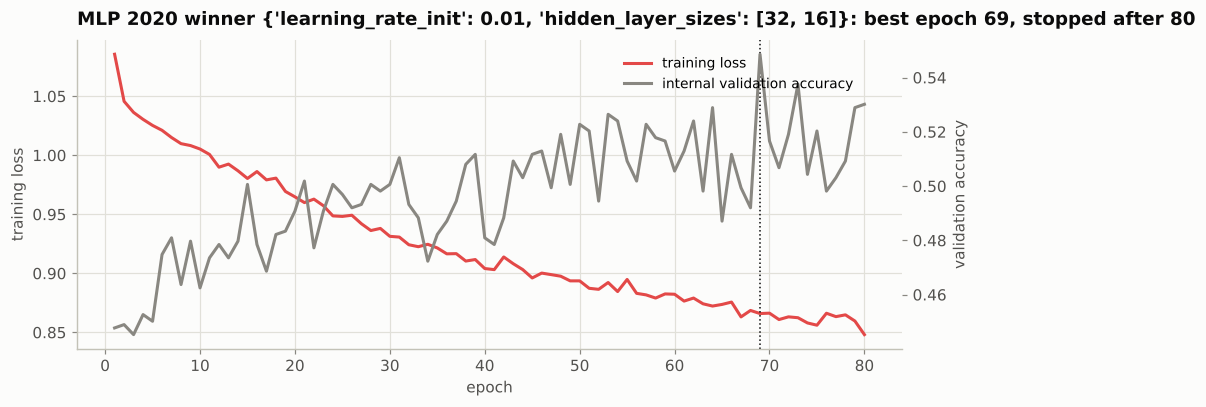

In [21]:
r = load_tuning("MLP", [2020])[2020]
cv_ = r["mlp_curves"]
fig, ax = plt.subplots(figsize=(9, 3.8)); ax2 = ax.twinx()
ax.plot(range(1, len(cv_["train_loss"]) + 1), cv_["train_loss"], color=P.MODEL_COLORS["MLP"], lw=2, label="training loss")
ax2.plot(range(1, len(cv_["val_accuracy"]) + 1), cv_["val_accuracy"], color=P.CLASS_COLORS["Hold"], lw=2, label="internal validation accuracy")
if cv_["best_epoch"]: ax.axvline(cv_["best_epoch"], color=P.INK, ls=":", lw=1)
ax.set_xlabel("epoch"); ax.set_ylabel("training loss"); ax2.set_ylabel("validation accuracy"); ax2.grid(False)
ax.set_title(f"MLP 2020 winner {r['grid'][r['winner']]['params']}: best epoch {cv_['best_epoch']}, stopped after {cv_['n_epochs']}")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88)); fig.tight_layout(); P.save(fig, "04_mlp_curves_2020")